# Multilayer RBNO

In [1]:

num_samples = 1000 #Size of the dataset

## 1. Sample the input for poisson problem from GP and solve
The goal is to perform operator learning on the poisson equation (in 2d on [0,1]^2):
$$\Delta u = -f_{cv}$$
Where we consider $f_{cv}$ as the input and the solution function $u$ as output.

To create a dataset, we sample $f_{cv}$ from a Gaussian process and solve the equation numerically to get $u_{sol}$.
The Dataset consists of num_samples tuples $(X,Y) = (f_{cv},u_{sol})$.



In [2]:
from fipy import Grid2D, CellVariable, DiffusionTerm, numerix as np
import numpy as onp
import matplotlib.pyplot as plt
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
from typing import Tuple

import jax
import jax.numpy as jnp
from jaxtyping import Float, Array



key = jax.random.PRNGKey(356)  # <-- correct key ctor

In [3]:
N = 100
L = 1.0
dx = L / N
mesh = Grid2D(nx=N, ny=N, dx=dx, dy=dx)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)
xc, yc = mesh.cellCenters

In [4]:

# --- stability: 64-bit helps Cholesky on larger grids ---
jax.config.update("jax_enable_x64", True)

@dataclass
class Gaussian:
    mu: Float[Array, "N"]
    Sigma: Float[Array, "N N"]
    jitter: float = 1e-6

    @cached_property
    def L(self) -> Float[Array, "N N"]:
        n = self.Sigma.shape[0]
        # enforce symmetry (tiny fp errors can hurt Cholesky)
        S = 0.5 * (self.Sigma + self.Sigma.T)
        return jnp.linalg.cholesky(S + self.jitter * jnp.eye(n, dtype=S.dtype))

    def sample(self, key: jax.random.KeyArray, num_samples: int = 1
               ) -> Float[Array, "num_samples N"]:
        n = self.mu.shape[0]
        z = jax.random.normal(key, shape=(num_samples, n), dtype=self.mu.dtype)
        return self.mu + z @ self.L.T


def rbf_kernel(
    X: Float[Array, "N 2"], Y: Float[Array, "M 2"],
    variance: float = 1.0, lengthscales: Tuple[float, float] = (0.2, 0.2),
    dtype=jnp.float64
) -> Float[Array, "N M"]:
    ℓx, ℓy = lengthscales
    Xs = X / jnp.array([ℓx, ℓy], dtype=dtype)
    Ys = Y / jnp.array([ℓx, ℓy], dtype=dtype)
    diff = Xs[:, None, :] - Ys[None, :, :]
    sqdist = jnp.sum(diff * diff, axis=-1)
    return jnp.asarray(variance, dtype=dtype) * jnp.exp(-0.5 * sqdist)


def sample_gp_on_grid(
    key: jax.random.KeyArray,
    nx: int = 80, ny: int = 80,
    xlim=(0.0, 1.0), ylim=(0.0, 1.0),
    variance: float = 1.0, lengthscales=(0.15, 0.25),
    jitter: float = 1e-5, num_samples: int = 1,
    dtype=jnp.float64
):
    xs = jnp.linspace(xlim[0], xlim[1], nx, dtype=dtype)
    ys = jnp.linspace(ylim[0], ylim[1], ny, dtype=dtype)
    Xg, Yg = jnp.meshgrid(xs, ys, indexing="xy")       # (ny, nx)
    XY = jnp.stack([Xg.ravel(), Yg.ravel()], axis=-1)  # (N,2), N=nx*ny

    K = rbf_kernel(XY, XY, variance=variance, lengthscales=lengthscales, dtype=dtype)
    mu = jnp.zeros(K.shape[0], dtype=dtype)
    gp = Gaussian(mu=mu, Sigma=K, jitter=jitter)

    key, sub = jax.random.split(key)
    samples_flat = gp.sample(sub, num_samples=num_samples)         # (S, N)
    samples_img = samples_flat.reshape(num_samples, ny, nx)        # (S, ny, nx)
    return samples_img, xs, ys

min: -4.393014899326931 max: 4.923566512901655 std: 2.1634213001926264 has_nan: False


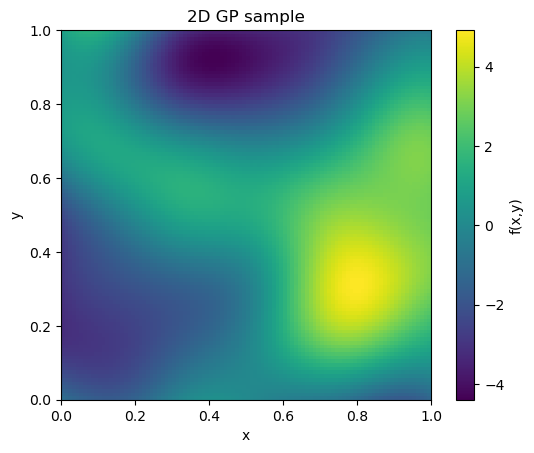

In [5]:
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.2, 0.2),
    jitter=1e-5, num_samples=1
)
s0 = onp.array(samples[2])  # to NumPy for plotting
print("min:", onp.nanmin(s0), "max:", onp.nanmax(s0), "std:", onp.nanstd(s0),
          "has_nan:", onp.isnan(s0).any())

# simplest, robust visualization:
plt.figure()
plt.imshow(s0, origin="lower", extent=[float(xs[0]), float(xs[-1]), float(ys[0]), float(ys[-1])], aspect="equal")
plt.colorbar(label="f(x,y)")
plt.title("2D GP sample")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

In [6]:
#We sample f_cv from the gaussian process and solve the Poisson equation with -f_cv as RHS

num_samples = 1000
frac_train = 0.7
solution = np.zeros(shape=(num_samples,N,N))
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.2, 0.2),
    jitter=1e-5, num_samples=num_samples
)
for i in range(len(samples)):
    s = onp.array(samples[i])  # to NumPy for plotting
    # s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
    s_flat = onp.asarray(s).ravel(order="C")              # length = N*N
    assert s_flat.size == mesh.numberOfCells

    f_cv = CellVariable(mesh=mesh, value=s_flat)

    u = CellVariable(name="u", mesh=mesh, value=0.0)
    u.constrain(0.0, where=mesh.exteriorFaces)
    eq = DiffusionTerm(var=u) == -f_cv
    eq.solve(var=u)
    u_grid = u.value.reshape((N, N), order="C")  # shape back to grid
    solution[i] = u_grid

In [7]:
X,Y = samples,solution

## 2. Offline PCA and calculation of reduced basis encoder and decoder
We first perform an offline PCA on snapshots of the input and outputs respectively.

In [8]:
#Normalize data
X, Y = onp.array(X),np.array(Y)
# Suppose X has shape (num_samples, N, N) or (num_samples, C, N, N)
x_mean = X.mean()
x_std  = X.std()

y_mean = Y.mean()
y_std  = Y.std()


Xn = (X - x_mean) / (x_std + 1e-8)
Yn = (Y - y_mean) / (y_std + 1e-8)

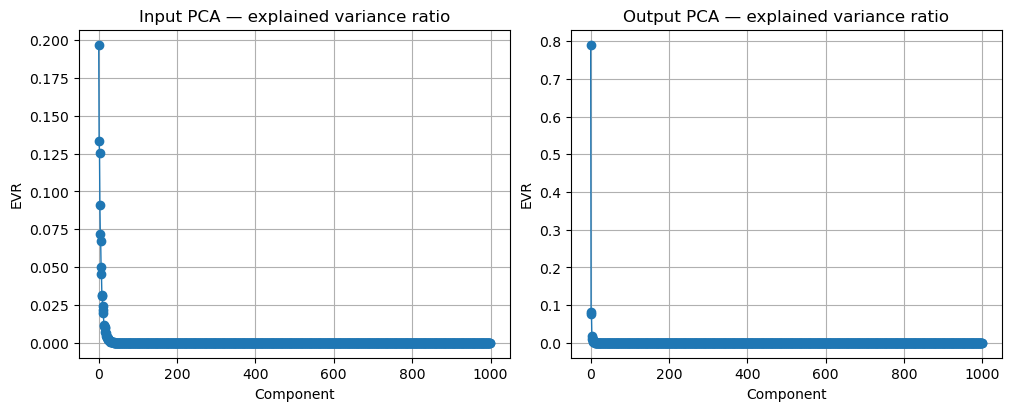

k_in:  79 k_out:  34


In [31]:

from sklearn.decomposition import PCA
from dataclasses import dataclass
from MRBNO_model import *
num_snapshots = num_samples
rb = PCAReducer().fit(Xn[:num_snapshots], Yn[:num_snapshots])
# Inspect spectra
rb.plot_explained_variance()

# Pick dimensions by cutoff (e.g., 99% variance)
epsilon = 1e-5
k_in, k_out = rb.k_from_cutoff(j_in=1-1*epsilon, j_out=1-epsilon)
print("k_in: ",k_in,"k_out: ", k_out)

In [32]:
# Reconstruct using PCA only (no neural network)
def test_pca_reconstruction(rb, X, Y,k_in,k_out):
    """Test if PCA itself works correctly"""
    X_flat = X.reshape(len(X), -1)
    Y_flat = Y.reshape(len(Y), -1)
    
    # Encode and decode X using output PCA
    X_c = X_flat - rb.pca_in.mean_
    X_coef = X_c @ rb.pca_in.components_[:k_in].T
    X_recon = X_coef @ rb.pca_in.components_[:k_in] + rb.pca_in.mean_
    X_recon = X_recon.reshape(X.shape)
    
    # Direct reconstruction of Y
    Y_c = Y_flat - rb.pca_out.mean_
    Y_coef = Y_c @ rb.pca_out.components_[:k_out].T
    Y_recon = Y_coef @ rb.pca_out.components_[:k_out] + rb.pca_out.mean_
    Y_recon = Y_recon.reshape(Y.shape)
    
    print("PCA Reconstruction Test:")
    print(f"X reconstruction error: {np.mean((X - X_recon)**2):.4e}")
    print(f"Y reconstruction error: {np.mean((Y - Y_recon)**2):.4e}")
    print(f"X->Y error (baseline): {np.mean((X - Y)**2):.4e}")
    
test_pca_reconstruction(rb, Xn, Yn,k_in,k_out)

PCA Reconstruction Test:
X reconstruction error: 9.4112e-06
Y reconstruction error: 9.6674e-06
X->Y error (baseline): 5.5701e-01


## 3. Architecture of multilayer reduced basis NO

In [33]:
# fno2d_train.py
from __future__ import annotations
import math
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn import BatchNorm2d
torch.set_default_dtype(torch.float32)

### Reduced Basis Resnet
This is one layer of the multilayer RBNO:
The input is mapped to its coefficients of the reduced basis. Then follows a Resnet on the coefficients,  which are the mapped back.
Basically:

z_in = encode(x)                    # (B, k_in)

h = F.gelu(in_lin(z_in))

h = ResNet(h)                       #Resnet of depth

z_out = out_lin(h)                  # (B, k_out)

y = self.decode(z_out)              # (B, D)

return y

### Multilayer RBNet
Now we stack multiple RB Resnet layers ontop of each other, together with a residual connection.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

del SimplifiedMultiLayerRBNet, MultiLayerReducedBasisResNet
from MRBNO_model import MultiLayerReducedBasisResNet, SimplifiedMultiLayerRBNet, IdentityInitRBNet, simple_train

### Training loop

In [51]:
train_frac = 0.7
X_train, Y_train = Xn[:int(train_frac*num_samples)], Yn[:int(train_frac*num_samples)]
X_val, Y_val = Xn[int(train_frac*num_samples):], Yn[int(train_frac*num_samples):]

In [ ]:
#good hyperparameters are:
model1 = MultiLayerReducedBasisResNet(
        rb, k_in=k_in, k_out=k_out,
        layers=5, hidden=64, depth=2, dropout=0.0
    )
model = model1

trained_model = simple_train(
        model, X_train, Y_train, X_val, Y_val,
        epochs=250, batch_size=16, lr=5e-3, weight_decay=1e-6,
        scheduler_step=30, scheduler_gamma=0.8)

Training on mps
Model parameters: 130,962
[001/250] train=6.0383e-01 val=3.2158e-01 lr=5.00e-03 (best: 3.2158e-01 @ epoch 1)
[010/250] train=4.2100e-02 val=4.6299e-02 lr=5.00e-03 (best: 4.6299e-02 @ epoch 10)
[020/250] train=2.1803e-02 val=2.6958e-02 lr=5.00e-03 (best: 2.6958e-02 @ epoch 20)
[030/250] train=1.9103e-02 val=2.8597e-02 lr=4.00e-03 (best: 2.1664e-02 @ epoch 26)
[040/250] train=1.4689e-02 val=1.9929e-02 lr=4.00e-03 (best: 1.9089e-02 @ epoch 37)
[050/250] train=1.1598e-02 val=1.7719e-02 lr=4.00e-03 (best: 1.7331e-02 @ epoch 49)
[060/250] train=1.2871e-02 val=1.7902e-02 lr=3.20e-03 (best: 1.6389e-02 @ epoch 53)
[070/250] train=8.8151e-03 val=1.4154e-02 lr=3.20e-03 (best: 1.3882e-02 @ epoch 67)
[080/250] train=9.7758e-03 val=1.4120e-02 lr=3.20e-03 (best: 1.3882e-02 @ epoch 67)
[090/250] train=1.0350e-02 val=1.5459e-02 lr=2.56e-03 (best: 1.3361e-02 @ epoch 89)
[100/250] train=6.5707e-03 val=1.2582e-02 lr=2.56e-03 (best: 1.2326e-02 @ epoch 96)
[110/250] train=7.6976e-03 val=1.35

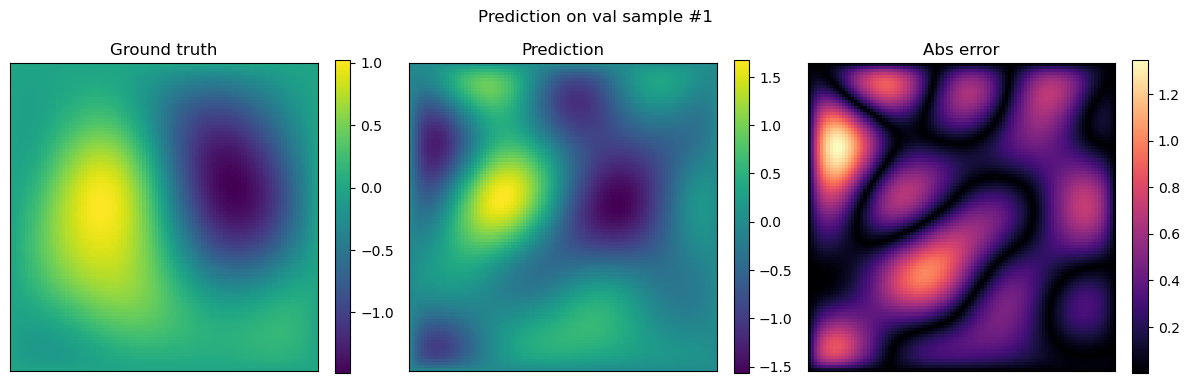

In [75]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# --- pick one sample from arrays X_val, Y_val ---
idx = 1  # choose which sample to visualize

# X_val: (B, C_in, N, N) or (B, N, N)
# Y_val: (B, 1, N, N)   or (B, N, N)
x_in  = X_val[idx]
y_true_arr = Y_val[idx]

# Ensure 3D field for y_true (N, N)
if y_true_arr.ndim == 3 and y_true_arr.shape[0] == 1:  # (1, N, N)
    y_true_2d = y_true_arr[0]
elif y_true_arr.ndim == 2:                             # (N, N)
    y_true_2d = y_true_arr
else:
    raise ValueError(f"Unexpected Y_val[idx] shape: {y_true_arr.shape}")

N = y_true_2d.shape[-1]

device = torch.device("cpu")
trained_model = trained
trained_model.to(device)
trained_model.eval()

# Build input tensor: (1, C_in, N, N)
if isinstance(x_in, np.ndarray):
    x_t = torch.from_numpy(x_in).to(dtype=torch.float32)
elif isinstance(x_in, torch.Tensor):
    x_t = x_in.detach().to(dtype=torch.float32)
else:
    raise TypeError("x_in must be numpy array or torch tensor")

# Add missing channel dim if needed: (N, N) -> (1, N, N)
if x_t.ndim == 2:
    x_t = x_t.unsqueeze(0)
# Add batch dim: (C_in, N, N) -> (1, C_in, N, N)
x_t = x_t.unsqueeze(0).to(device, non_blocking=True)

with torch.no_grad():
    y_pred_t = trained_model(x_t)            # expect (1, 1, N, N) or (1, N, N)
    # Squeeze batch/channel safely back to (N, N)
    if y_pred_t.ndim == 4 and y_pred_t.shape[1] == 1:
        y_pred_2d = y_pred_t[0, 0].cpu().numpy()
    elif y_pred_t.ndim == 3:
        y_pred_2d = y_pred_t[0].cpu().numpy()
    else:
        raise ValueError(f"Unexpected model output shape: {tuple(y_pred_t.shape)}")

y_true = y_true_2d  # already numpy (N, N)
y_pred = y_pred_2d  # numpy (N, N)


# --- plot ---
fig, axs = plt.subplots(1, 3, figsize=(12, 4))

im0 = axs[0].imshow(y_true, origin="lower", cmap="viridis")
axs[0].set_title("Ground truth")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(y_pred, origin="lower", cmap="viridis")
axs[1].set_title("Prediction")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

im2 = axs[2].imshow(np.abs(y_pred - y_true), origin="lower", cmap="magma")
axs[2].set_title("Abs error")
plt.colorbar(im2, ax=axs[2], fraction=0.046)

for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f"Prediction on val sample #{idx}")
plt.tight_layout()
plt.show()
